# Truncated Linear Models for Functional Data, Method A (Hall & Hooker 2016)

As in the companion method B notebook, suppose we have simulated data where the response $Y_i \in \mathbb{R}$ depends only on the curve $X_i \in L^2(I)$ over a window $[u, v] \subseteq I$:

$$Y_i = \int_u^v X_i(t) \, dt + \varepsilon_i, \qquad \varepsilon_i \sim N(0, \sigma^2),$$

so the true coefficient function is $\beta(t) = \mathbb{1}_{[u, v]}(t)$. We again take $I=[0,1]$, $u=0.8$, $v=1.0$, and generate data with `HH_dgp`.

Method B froze a single untruncated pilot $(\check a, \check b)$ and searched only over the endpoint. Method A instead re-estimates the model *simultaneously* with the endpoint: for every candidate $\theta$ it refits $(a, b)$ by least squares in the basis of empirical FPCs of the *truncated* curves $X_i(t)\,\mathbb{1}_{\{t<\theta\}}$ (the paper's $\psi_j = \hat\phi_j^{\,\theta}$), minimising

$$S(a, \beta_1, \dots, \beta_m, \theta \mid m, \lambda) = \sum_i \Big(Y_i - a - \int_0^\theta \textstyle\sum_j \beta_j \psi_j \, X_i\Big)^2 + n\lambda\theta^2. \tag{3.4}$$

A separate principal components analysis at each $\theta$ costs more than method B's single one, and the paper's Table 1 reports that it buys less bias in $\hat u$. We check that here.

We start by importing the packages and generating our data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fts_research.truncFLR import HH, HH_A, HH_dgp

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

u, v = 0.8, 1.0
lambdas = np.linspace(0.0, 1.0, 250)[1:]
data = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=123)
grid, X, Y = data["grid"], data["X"], data["Y"]

Method A does not *use* a frozen pilot for its endpoint search, but it still needs one to build the $\lambda$-selection criterion: the residual variance $\hat\sigma^2$, the parametric target $\tilde b_{simp}$, and the noiseless target $\bar Y^*_i = \check a + \int \tilde b_{simp} X_i$. We fit the same BIC-selected FPCA pilot as in method B and plot it against the truth.

In [2]:
a_pilot, b_pilot, fpc = HH_A.pilot_fpca(X, Y, grid)
print(f"BIC-selected number of FPCs: m = {fpc['m']}")
print(f"pilot intercept a_pilot = {a_pilot:.4f}")

BIC-selected number of FPCs: m = 9
pilot intercept a_pilot = -0.0018


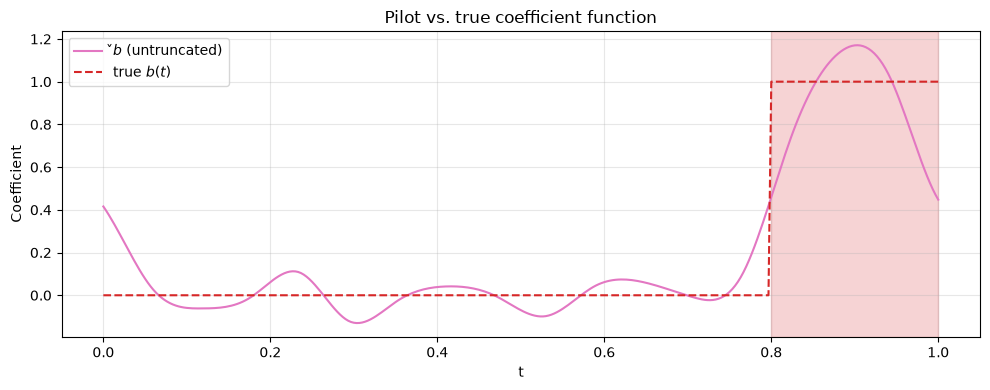

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(grid, b_pilot, color="C6", lw=1.5, label=r"$\check{b}$ (untruncated)")
plt.plot(grid, data["b"], color="C3", lw=1.5, ls="--", label=r"true $b(t)$")
plt.axvspan(u, v, color="C3", alpha=0.2)
plt.title("Pilot vs. true coefficient function")
plt.xlabel("t"); plt.ylabel("Coefficient")
plt.legend(); plt.tight_layout(); plt.show()

As with method B, the pilot leaks into the null region. Method A recovers the boundary not by truncating this pilot, but by refitting a fresh truncated model at each candidate endpoint and letting the penalised fit decide where the window ends.

Standard selection criteria fail here just as in method B, so Hall & Hooker again score $\lambda$ by how well the parametric $\tilde b_{simp}$ can be reconstructed after truncation. The two error curves take their method A forms (steps 4–5, not method B's primed $4'$–$5'$):

- $S_Y^A(\theta) = \sum_i \{\bar Y^*_i - \hat Y^*_i(\theta)\}^2 + \hat\sigma^2 (m+1)$, prediction error, where at each $\theta$ the target $(a^*_\theta, b^*_\theta)$ is refit onto the *truncated* FPCs. The variance term is the constant $\hat\sigma^2(m{+}1)$, i.e. the prediction variance of an $(m{+}1)$-parameter least-squares fit;
- $S_b^A(\theta) = \int_I (\tilde b_{simp} - b^*_\theta)^2 + \hat\sigma^2 \sum_{j=1}^m (\tau_j^\theta)^{-1}$, coefficient reconstruction error.

The selected $\lambda$ minimises $P_b(\lambda) = \int S_b^A(\theta)\, N(\theta;\theta_\lambda, V(\lambda))\, d\theta$, with $\theta_\lambda = \arg\min_\theta \{S_Y^A(\theta) + n\lambda\theta^2\}$, i.e. the *global* argmin. Method A has no analogue of method B's first-minimum rule. The scale of $\lambda$ in $V(\lambda)$ and the quadrature of the step-7 integral are as described in `truncFLR_lambdadegen.ipynb`.

We choose the number of components for the final fit separately, by BIC (step 7). This is `fit_mirror`'s default, and it matters: at a fixed large $m$ the objective (3.4) flattens in $\theta$ and the endpoint estimate wanders.

In [4]:
res = HH_A.fit_mirror(X, Y, grid, lambdas)
u_hat, b_hat, lam_hat, diag = res["u_hat"], res["b_hat"], res["lam_hat"], res["diag"]

idx = int(np.searchsorted(lambdas, lam_hat))
print(f"selected lambda = {lam_hat:.4g}  (candidate {idx + 1} of {len(lambdas)})")
print(f"BIC-selected final m = {res['m_hat']}")
print(f"estimated endpoint u_hat = {u_hat:.4f} (true u = {u})")

selected lambda = 0.008032  (candidate 2 of 249)
BIC-selected final m = 2
estimated endpoint u_hat = 0.7967 (true u = 0.8)


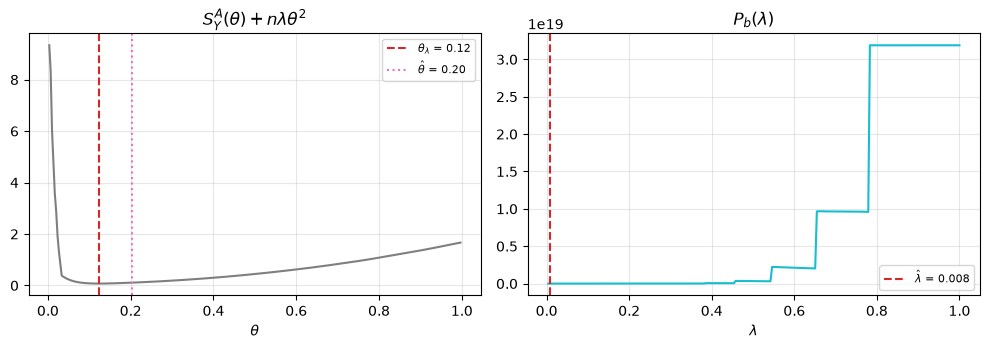

In [5]:
tg, S_Y, S_b, P_b = diag["theta_grid"], diag["S_Y"], diag["S_b"], diag["P_b"]
theta_lam = diag["theta_lams"][int(np.nanargmin(P_b))]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(tg, S_Y + len(Y) * lam_hat * tg ** 2, color="C7", lw=1.5)
ax[0].axvline(theta_lam, color="C3", ls="--", label=fr"$\theta_\lambda$ = {theta_lam:.2f}")
ax[0].axvline(res["theta_hat"], color="C6", ls=":",
              label=fr"$\hat\theta$ = {res['theta_hat']:.2f}")
ax[0].set_xlabel(r"$\theta$"); ax[0].set_title(r"$S_Y^A(\theta) + n\lambda\theta^2$")
ax[0].legend(fontsize=8)

ax[1].plot(lambdas, P_b, color="C9", lw=1.5)
ax[1].axvline(lam_hat, color="C3", ls="--", label=fr"$\hat\lambda$ = {lam_hat:.3f}")
ax[1].set_xlabel(r"$\lambda$"); ax[1].set_title(r"$P_b(\lambda)$")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Method A's $\hat\lambda$ is the second candidate of 249 here, and it sits at the bottom of the
grid on many seeds: the degeneracy notebook finds an interior $\hat\lambda$ on 10 of 25, against
method B's 23. That costs method A very little, and the reason is worth stating. Method B's
frozen pilot $\check b$ is fitted on the whole interval, and $S_Y^B$ drops away near the
right-hand end, so the penalty is the only thing pulling $\hat\theta$ back. Method A refits
$(a, b)$ on $[0, \theta]$ at every candidate, so a $\theta$ that is too large is already paid
for in the fit itself and needs less help from $\lambda\theta^2$.

Method B truncates its frozen pilot at $\hat u$, or refits on the restricted domain. Method A instead reports the truncated model it already refit at $\hat\theta$: $(a, b)$ estimated by least squares on $[0, \hat\theta]$ in the truncated FPC basis, at the BIC-selected number of components. We plot it against the pilot and the truth, and compare integrated squared error.

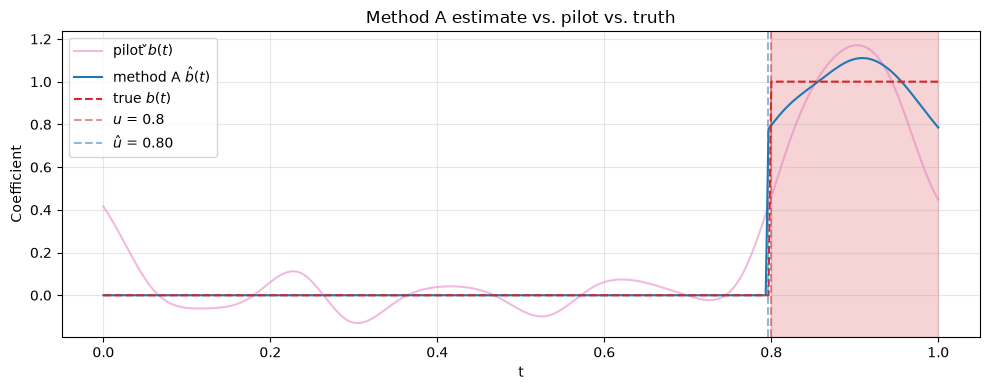

ISE, untruncated pilot   : 0.0211
ISE, method A estimate   : 0.0040


In [6]:
plt.figure(figsize=(10, 4))
plt.plot(grid, b_pilot, color="C6", lw=1.5, alpha=0.5, label=r"pilot $\check{b}(t)$")
plt.plot(grid, b_hat, color="C0", lw=1.5, label=r"method A $\hat{b}(t)$")
plt.plot(grid, data["b"], color="C3", lw=1.5, ls="--", label=r"true $b(t)$")
plt.axvline(u, color="C3", alpha=0.5, ls="--", label=fr"$u$ = {u}")
plt.axvline(u_hat, color="C0", alpha=0.5, ls="--", label=fr"$\hat u$ = {u_hat:.2f}")
plt.axvspan(u, v, color="C3", alpha=0.2)
plt.title("Method A estimate vs. pilot vs. truth")
plt.xlabel("t"); plt.ylabel("Coefficient")
plt.legend(); plt.tight_layout(); plt.show()

print(f"ISE, untruncated pilot   : {np.trapezoid((b_pilot - data['b']) ** 2, grid):.4f}")
print(f"ISE, method A estimate   : {np.trapezoid((b_hat - data['b']) ** 2, grid):.4f}")

## Method A against method B

The paper's Table 1 reports that method A carries less bias in $\hat u$ than method B, at the cost of a separate principal components analysis at every candidate $\theta$. We test that directly: both methods run on the *same* 100 datasets, so the comparison is paired and the standard error of the difference is the one that matters.

In [7]:
n_reps = 100
u_err = {"method A": np.empty(n_reps), "method B": np.empty(n_reps)}
ise = {"method A": np.empty(n_reps), "method B": np.empty(n_reps)}
m_hats = np.empty(n_reps, dtype=int)

for r in range(n_reps):
    d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=r)
    ra = HH_A.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
    rb = HH.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
    m_hats[r] = ra["m_hat"]
    for name, res in [("method A", ra), ("method B", rb)]:
        u_err[name][r] = res["u_hat"] - d["u"]
        ise[name][r] = np.trapezoid((res["b_hat"] - d["b"]) ** 2, d["grid"])

print(f"{n_reps} paired replications, n=200, n_grid=301, snr=26.25\n")
print(f"{'method':10} {'bias(u)':>9} {'sd(u)':>8} {'RMSE(u)':>9} {'mean ISE':>10}")
for name in ("method A", "method B"):
    e = u_err[name]
    print(f"{name:10} {e.mean():+9.4f} {e.std(ddof=1):8.4f} "
          f"{np.sqrt((e ** 2).mean()):9.4f} {ise[name].mean():10.4f}")
print(f"\nmedian BIC-selected m for method A: {int(np.median(m_hats))}")

100 paired replications, n=200, n_grid=301, snr=26.25

method       bias(u)    sd(u)   RMSE(u)   mean ISE
method A     -0.0023   0.0078    0.0081     0.0073
method B     -0.0017   0.0102    0.0103     0.0070

median BIC-selected m for method A: 2


In [8]:
d_bias = np.abs(u_err["method A"]) - np.abs(u_err["method B"])
d_ise = ise["method A"] - ise["method B"]
for label, d in [("|u_hat - u|", d_bias), ("ISE", d_ise)]:
    se = d.std(ddof=1) / np.sqrt(n_reps)
    print(f"paired A - B in {label:12}: {d.mean():+.5f}  se {se:.5f}  t {d.mean() / se:+.2f}")

paired A - B in |u_hat - u| : -0.00027  se 0.00068  t -0.39
paired A - B in ISE         : +0.00032  se 0.00040  t +0.80


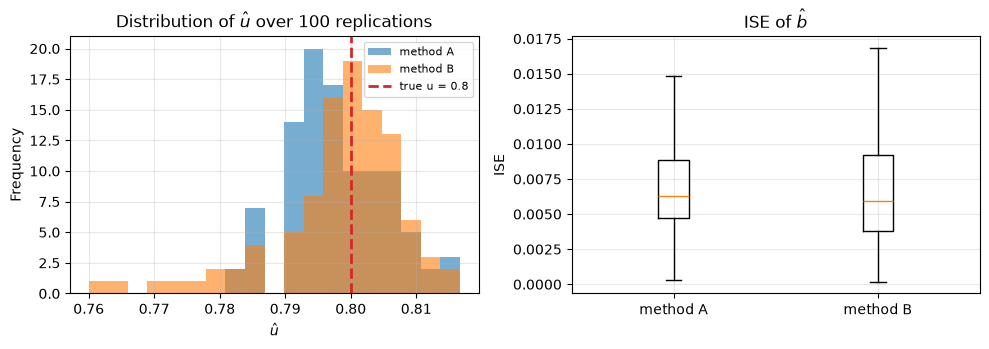

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.linspace(min(u_err["method A"].min(), u_err["method B"].min()) + u,
                   max(u_err["method A"].max(), u_err["method B"].max()) + u, 20)
for name, colour in [("method A", "C0"), ("method B", "C1")]:
    ax[0].hist(u_err[name] + u, bins=bins, alpha=0.6, color=colour, label=name)
ax[0].axvline(u, color="C3", lw=2, ls="--", label=f"true u = {u}")
ax[0].set_xlabel(r"$\hat u$"); ax[0].set_ylabel("Frequency")
ax[0].set_title(fr"Distribution of $\hat u$ over {n_reps} replications")
ax[0].legend(fontsize=8)

ax[1].boxplot([ise["method A"], ise["method B"]],
              tick_labels=["method A", "method B"], showfliers=False)
ax[1].set_ylabel("ISE"); ax[1].set_title(r"ISE of $\hat b$")
plt.tight_layout(); plt.show()

The two methods are indistinguishable here. Method A is marginally the less variable, at a
sampling standard deviation of 0.0078 against 0.0102, and method B has the marginally lower mean
ISE, but the paired differences are within noise on both: $t = -0.39$ in absolute endpoint error
and $t = +0.80$ in ISE, over 100 datasets each method saw.

That is not what the paper's Table 1 reports, and not what this repository found before §3.2 was
put on its own scale. The gap was method B's tuning rather than method B: run as the section 3.2
displays are written, its $\hat\lambda$ is the smallest candidate on the grid whatever the data,
the penalty does nothing, and the endpoint comes back short by about nine grid steps — which is
exactly the under-truncation Table 1 attributes to the method. With the penalty restored, method
B recovers the endpoint as well as method A does, and at a fraction of the cost: one principal
components analysis against a fresh one at every candidate $\theta$. What the correction removes
is not method A's advantage but the reason for it. `truncFLR_lambdadegen.ipynb` has the
derivation and the measurements.

The indicator window is the easiest case, a jump being the most detectable boundary. Models 2 and 3 in the paper let $b$ approach zero *smoothly* at the endpoint, which makes truncation harder. We generate a half-sine bump on $[0.8, 1]$ and watch the estimator degrade.

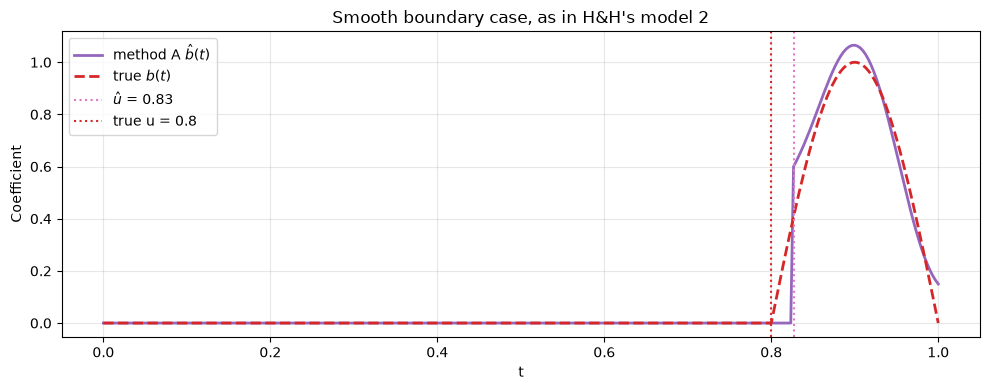

In [10]:
def beta_bump(t, u=u, v=v):
    w = (t >= u) & (t <= v)
    b = np.zeros_like(t)
    b[w] = np.sin(np.pi * (t[w] - u) / (v - u))
    return b


d_bump = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25,
                            beta_fn=beta_bump, rng=123)
res_bump = HH_A.fit_mirror(d_bump["X"], d_bump["Y"], d_bump["grid"], lambdas)

plt.figure(figsize=(10, 4))
plt.plot(d_bump["grid"], res_bump["b_hat"], color="C4", lw=2, label=r"method A $\hat{b}(t)$")
plt.plot(d_bump["grid"], d_bump["b"], color="C3", lw=2, ls="--", label=r"true $b(t)$")
plt.axvline(res_bump["u_hat"], color="C6", ls=":",
            label=fr"$\hat u$ = {res_bump['u_hat']:.2f}")
plt.axvline(u, color="C3", ls=":", label=f"true u = {u}")
plt.title("Smooth boundary case, as in H&H's model 2")
plt.xlabel("t"); plt.ylabel("Coefficient")
plt.legend(); plt.tight_layout(); plt.show()

## Two readings of step 7

The paper's step 7 for method A reads: *"For this $\lambda$ we determine $\hat a$ and $\hat b$ from the original data via method A for each choice of $m$. We repeat the process above for each $m$, and we select $m$ by minimizing BIC."*

$m$ appears inside the $\lambda$-selection as well as in the final fit, since $S_Y^A$ carries a $\hat\sigma^2(m{+}1)$ term and $S_b^A$ sums $(\tau_j^\theta)^{-1}$ to $m$. The two readings are not the same estimator:

- `strict=False` (default): select $\lambda$ once, then loop only the final fit over $m$ and pick $m$ by BIC;
- `strict=True`: re-run the whole $\lambda$-selection for every candidate $m$, so each $m$ carries its own $\hat\lambda_m$, then BIC-select over the pairs. Costs $|\texttt{m\_range}|$ selections, and exposes the per-$m$ penalties under `diag["lam_hats"]`.

We run both on several seeds.

In [11]:
print(f"{'seed':>4} | {'u_fast':>7} {'m_fast':>6} | {'u_strict':>8} {'m_strict':>8} "
      f"| {'lam_fast':>9} {'lam_strict':>10} | same")
agree = 0
for seed in range(8):
    d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=seed)
    fast = HH_A.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
    strict = HH_A.fit_mirror(d["X"], d["Y"], d["grid"], lambdas, strict=True)
    same = (fast["m_hat"] == strict["m_hat"]) and (fast["u_hat"] == strict["u_hat"])
    agree += same
    print(f"{seed:>4} | {fast['u_hat']:7.4f} {fast['m_hat']:6d} | {strict['u_hat']:8.4f} "
          f"{strict['m_hat']:8d} | {fast['lam_hat']:9.4f} {strict['lam_hat']:10.4f} | {same}")
print(f"\nidentical on {agree}/8 seeds")

seed |  u_fast m_fast | u_strict m_strict |  lam_fast lam_strict | same


   0 |  0.7867      2 |   0.7867        2 |    0.0040     0.0040 | True


   1 |  0.7933      2 |   0.8033        3 |    0.0080     0.0040 | False


   2 |  0.8067      3 |   0.8067        3 |    0.0080     0.0161 | True


   3 |  0.8033      3 |   0.8067        3 |    0.0040     0.0080 | False


   4 |  0.7933      2 |   0.8000        2 |    0.0040     0.0201 | False


   5 |  0.7933      2 |   0.8033        3 |    0.0080     0.0040 | False


   6 |  0.7933      2 |   0.8033        3 |    0.0040     0.0120 | False


   7 |  0.7967      2 |   0.8033        3 |    0.0080     0.0080 | False

identical on 2/8 seeds


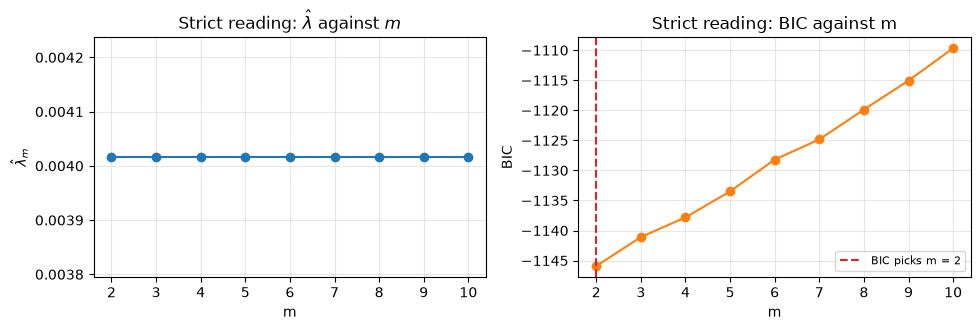

In [12]:
d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=0)
strict = HH_A.fit_mirror(d["X"], d["Y"], d["grid"], lambdas, strict=True)
lam_hats, bics = strict["diag"]["lam_hats"], strict["diag"]["bics"]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ms = sorted(lam_hats)
ax[0].plot(ms, [lam_hats[m] for m in ms], marker="o", color="C0")
ax[0].set_xlabel("m"); ax[0].set_ylabel(r"$\hat\lambda_m$")
ax[0].set_title(r"Strict reading: $\hat\lambda$ against $m$")
ax[1].plot(ms, [bics[m] for m in ms], marker="o", color="C1")
ax[1].axvline(strict["m_hat"], color="C3", ls="--", label=f"BIC picks m = {strict['m_hat']}")
ax[1].set_xlabel("m"); ax[1].set_ylabel("BIC")
ax[1].set_title("Strict reading: BIC against m")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

We can see that $\hat\lambda_m$ genuinely varies with $m$, so the two readings are not interchangeable and the seeds where they land on the same $(\hat m, \hat u)$ do so by coincidence rather than by construction. The fast path commits to one $\lambda$ chosen at the pilot's component budget and then lets BIC move $m$ underneath it; the strict path lets each $m$ carry the penalty its own criterion asks for. Where they differ, the strict reading is the one that follows the text, and the fast one is a computational shortcut worth roughly a factor of $|\texttt{m\_range}|$.